# Phân loại tám nhóm tổn thương da ISIC 2019 — T02B
**Nguyễn Tuấn Đức — MSSV 2351067091**

Notebook trình bày một luồng: **ResNet50 ImageNet V1 → D4 khi train → Cross-Entropy không trọng số**. Các thí nghiệm khác chỉ xuất hiện trong bảng Markdown để giải thích quyết định, không có bộ chạy hàng loạt.

**T02B là cấu hình được giữ hiện hành**, không phải phương án luôn tốt nhất: L01 nhỉnh hơn 0,0249 điểm phần trăm ở một seed nhưng chưa đủ bằng chứng thay đổi. Bản gọn này là mã tổ chức lại, **đã chạy phần báo cáo và demo trên Kaggle; nhánh train chưa chạy**. Kết quả lịch sử được đọc từ file; không giả làm output huấn luyện mới.

**Ba Input trên Kaggle:** (1) `data_ISIC2019_Bao_cao_tong_hop_v1_0` có thư mục `data` và `REPORT_INPUT_HASHES.json`; (2) dataset ảnh `salviohexia/isic-2019-skin-lesion-images-for-classification`; (3) FULL Output T02AB chứa checkpoint T02B `best_resnet50.pt`. Không cần gắn output P01–P10 cho bản gọn.

**Cách chạy:** mặc định chỉ báo cáo, `RUN_TRAIN=False`, `RUN_DEMO=False`. Muốn demo bật `RUN_DEMO=True` ở phần 8 sau khi chạy phần trước. Huấn luyện mới cần T4 và môi trường khóa; không cần train lại để trình bày. Không suy luận test mới. Nếu Pillow lệch, chạy `%pip install --no-deps "Pillow==12.3.0"` trong cell riêng, restart kernel rồi chạy lại; không thay chuỗi phiên bản để vượt kiểm tra.

## 1. EDA, kiểm toán dữ liệu và tập chia
Ảnh soi da là đầu vào; nhãn là một trong tám nhóm tổn thương, **không phải tất cả đều là ung thư**. Thứ tự đầu ra phải giữ **MEL, NV, BCC, AK, BKL, DF, VASC, SCC** theo checkpoint; không đổi theo thứ tự số lượng ảnh.

| Nội dung | Kết quả lịch sử |
|---|---:|
| Ảnh có nhãn ban đầu | **25.331** |
| Ảnh trùng dư (`exact_duplicate_excess`) | **48** — không đồng nghĩa 48 cặp |
| Ảnh xung đột nhãn bị loại | **4** |
| Ảnh giữ lại trong manifest | **25.327** |
| Train / validation / test nội bộ | **17.723 / 2.539 / 5.065** |
| Thiếu lesion_id | **2.084** |

Nguồn: `reference/historical_data_audit.json`, `split_manifest.csv`. Dùng split lịch sử đã khóa, không chia lại. Group được dựng theo tổn thương và ảnh trùng nội dung; kiểm crossing = 0 cho định danh có dữ liệu. Thiếu patient_id, thiếu lesion_id và ảnh gần trùng khác bytes vẫn là giới hạn; không gọi đây là dữ liệu hoàn toàn sạch hay khẳng định hết leakage.

Metadata được ghép bằng image để kiểm độ bao phủ, **không làm đầu vào cho mô hình ảnh**. Các thống kê của train dùng cho mô tả huấn luyện. Test nội bộ đã đánh giá ở giai đoạn chốt trước đây; hiện chỉ đọc kết quả lưu, không còn gọi là test chưa từng mở.

In [2]:
from pathlib import Path
from datetime import datetime
import json, hashlib, random, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    precision_recall_fscore_support, confusion_matrix)
from IPython.display import display

LABELS = ['MEL','NV','BCC','AK','BKL','DF','VASC','SCC']
SEED, SIZE, BATCH, WORKERS = 42, 224, 32, 2
EPOCHS, PATIENCE, MIN_DELTA = 16, 4, 1e-5
RUN_TRAIN = False
REPORT_DATA = None  # Điền thư mục data nếu có nhiều bản cùng gắn vào Input.
IMAGE_ROOT = Path('/kaggle/input')  # Có thể chỉ rõ thư mục dataset ảnh.
CHECKPOINT_PATH = None  # None: tự tìm checkpoint lịch sử theo hash.
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT = (Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd()) / ('T02B_CLEAN_' + datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
OUT.mkdir(parents=True, exist_ok=False)

def sha_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(1024*1024), b''):
            h.update(block)
    return h.hexdigest()

def save_json(path, obj):
    Path(path).write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding='utf-8')

if REPORT_DATA is None:
    candidates = sorted({p.parent for p in IMAGE_ROOT.rglob('ISIC2019_REPORT_PACKAGE.json')})
    assert len(candidates) == 1, f'Điền REPORT_DATA: tìm được {candidates}'
    REPORT_DATA = candidates[0]
REPORT_DATA = Path(REPORT_DATA)
assert sha_file(REPORT_DATA/'REPORT_INPUT_HASHES.json') == '484f625fe653f577b4a9a3020e5e21cca07123f3418249cc7a62128d716b52b2'
for name, digest in json.loads((REPORT_DATA/'REPORT_INPUT_HASHES.json').read_text()).items():
    assert sha_file(REPORT_DATA/name) == digest, f'Sai nguồn: {name}'
def read_json(name):
    return json.loads((REPORT_DATA/name).read_text(encoding='utf-8'))
lock = read_json('reference/candidate_protocol_lock.json')
complete = read_json('reference/complete.json')
assert lock['method'] == complete['method'] == 'T02B_D4_R50'
assert LABELS == lock['baseline_config']['labels']
for key,value in [('seed',SEED),('size',SIZE),('batch',BATCH),('epochs',EPOCHS),('patience',PATIENCE)]:
    assert lock['baseline_config'][key] == value
assert complete['checkpoint_sha'] == read_json('test_report/final_test/config.json')['checkpoint_sha']
print('Nguồn lịch sử khớp hash. Output mới:', OUT)

Nguồn lịch sử khớp hash. Output mới: /kaggle/working/T02B_CLEAN_20261027_001944_940980


### Giải thích kết quả kiểm nguồn

Thông báo **“Nguồn lịch sử khớp hash”** cho biết các file đầu vào khớp với bản đã khóa. Hash là mã dùng để kiểm tra nội dung file có thay đổi hay không.

Đường dẫn **Output mới** là nơi lưu kết quả của phiên đang chạy, không ghi đè dữ liệu nguồn.

Kiểm tra này giúp tránh trộn nhầm các lần thí nghiệm; **không chứng minh mô hình dự đoán tốt**.

,định danh,số giá trị vượt split,số dòng thiếu
0,image,0,0
1,group,0,0
2,file_sha256,0,0
3,lesion_id,0,2084


Không có patient_id trong manifest: True
Metadata: 25331 ảnh; ngoài manifest: 4


split,train,val,test
label_name,,,
MEL,3077,478,965
NV,9019,1247,2607
BCC,2374,348,601
AK,611,84,172
BKL,1847,285,492
DF,187,20,32
VASC,151,22,80
SCC,457,55,116


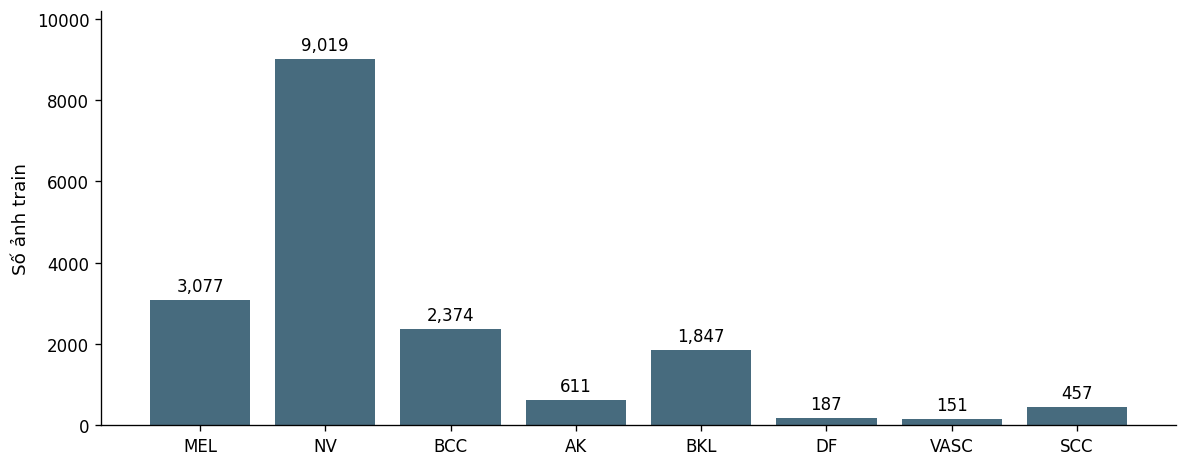

,original,retained,excluded_conflicting_images,missing_lesion_id,exact_duplicate_excess,groundtruth_sha,metadata_sha
0,25331,25327,4,2084,48,aa88e9638fe4df9ef330dc4ba22fa4bd475c44af692fff...,d93994a8ed201d474de9a7af7e17ec30929cbc4a522065...


In [3]:
manifest = pd.read_csv(
    REPORT_DATA / 'split_manifest.csv',
    keep_default_na=False
)

assert manifest.image.is_unique and len(manifest) == 25327

parts = {
    s: manifest[manifest.split.eq(s)].copy()
    for s in ['train', 'val', 'test']
}

assert {s: len(d) for s, d in parts.items()} == {
    'train': 17723,
    'val': 2539,
    'test': 5065
}

assert (
    manifest.label_name.map(dict(zip(LABELS, range(8))))
    == manifest.label
).all()

# Kiểm tra các định danh có xuất hiện ở nhiều tập hay không
leakage_checks = []

for key in ['image', 'group', 'file_sha256', 'lesion_id']:
    known = manifest[key].astype(str).str.strip().ne('')

    crossing = (
        manifest.loc[known].groupby(key).split.nunique() > 1
    ).sum()

    assert crossing == 0, f'Có {key} vượt split'

    leakage_checks.append({
        'định danh': key,
        'số giá trị vượt split': int(crossing),
        'số dòng thiếu': int((~known).sum())
    })

display(pd.DataFrame(leakage_checks))

print(
    'Không có patient_id trong manifest:',
    'patient_id' not in manifest.columns
)

# Đối chiếu với metadata gốc
metadata_files = sorted(
    p for p in IMAGE_ROOT.rglob('ISIC_2019_Training_Metadata.csv')
    if '.ipynb_checkpoints' not in p.parts
)

assert len(metadata_files) == 1, (
    'Cần đúng một metadata CSV; kiểm lại Input ảnh.'
)

metadata = pd.read_csv(metadata_files[0], keep_default_na=False)
assert metadata.image.is_unique

joined = manifest[['image']].merge(
    metadata,
    on='image',
    how='left',
    validate='one_to_one',
    indicator=True
)

assert joined['_merge'].eq('both').all()

print(
    'Metadata:', len(metadata),
    'ảnh; ngoài manifest:',
    len(set(metadata.image) - set(manifest.image))
)

# Thống kê số ảnh theo lớp và tập dữ liệu
counts = (
    pd.crosstab(manifest.label_name, manifest.split)
    .reindex(LABELS)[['train', 'val', 'test']]
)

assert counts.train.tolist() == [
    3077, 9019, 2374, 611, 1847, 187, 151, 457
]

display(counts)
counts.to_csv(OUT / 'class_counts.csv')

# Vẽ biểu đồ giống ảnh mẫu, lấy trực tiếp số liệu từ counts
train_counts = counts.loc[LABELS, 'train']

with plt.rc_context({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'text.color': 'black',
    'axes.labelcolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black',
    'axes.edgecolor': 'black'
}):
    fig, ax = plt.subplots(figsize=(10, 4), dpi=120)

    bars = ax.bar(
        train_counts.index,
        train_counts.values,
        color='#476B7E',
        width=0.8,
        linewidth=0
    )

    # Ghi số lượng ảnh phía trên từng cột
    ax.bar_label(
        bars,
        labels=[f'{int(n):,}' for n in train_counts.values],
        padding=3,
        fontsize=10
    )

    ax.set_ylabel('Số ảnh train', fontsize=11)
    ax.set_xlabel('')
    ax.tick_params(axis='both', labelsize=10)
    ax.tick_params(axis='x', rotation=0)

    # Giữ trục tuyến tính từ 0 để thể hiện đúng mức mất cân bằng
    ax.set_ylim(0, train_counts.max() * 1.13)

    # Bỏ viền trên, viền phải và đường lưới như ảnh mẫu
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(True)
    ax.spines['bottom'].set_visible(True)
    ax.grid(False)

    fig.tight_layout()
    plt.show()

# Hiển thị kết quả kiểm tra dữ liệu trước đây
display(pd.DataFrame([
    read_json('reference/historical_data_audit.json')
]))

### Đọc kết quả kiểm dữ liệu và phân bố lớp

**1. Bảng kiểm rò rỉ:** cột “số giá trị vượt split” đều bằng 0, nghĩa là các định danh đã biết không xuất hiện ở nhiều tập. Tuy nhiên, có **2.084 ảnh thiếu lesion_id** và không có patient_id, nên chưa thể khẳng định đã loại trừ mọi nguy cơ rò rỉ.

**2. Bảng số lượng ảnh:** mỗi hàng là một lớp; ba cột là:
- **Train: 17.723 ảnh** — dùng để mô hình học.
- **Validation: 2.539 ảnh** — dùng chọn checkpoint và so sánh phương án.
- **Test nội bộ: 5.065 ảnh** — dùng đánh giá phương án đã chốt.

**3. Biểu đồ cột:** thể hiện số ảnh train, không phải độ chính xác. NV có **9.019 ảnh**, còn VASC chỉ **151 ảnh**: số ảnh NV nhiều hơn khoảng **60 lần**.

Vì dữ liệu lệch lớp, em dùng **Macro-F1** làm tiêu chí chính: tính F1 từng lớp rồi lấy trung bình, mỗi lớp có trọng số ngang nhau. Accuracy vẫn được báo cáo nhưng có thể bị lớp đông ảnh chi phối.

**4. Bảng audit:** từ **25.331 ảnh ban đầu**, loại **4 ảnh xung đột nhãn**, còn **25.327 ảnh** trong manifest. Giá trị `exact_duplicate_excess = 48` là số ảnh trùng dư, không đồng nghĩa với 48 cặp ảnh.

## 2. Tiền xử lý cố định và augmentation D4
Luồng ảnh: **RGB → resize bilinear 224×224 → D4 nếu train → tensor → chuẩn hóa ImageNet**. Normalize áp dụng `(x - mean) / std` theo kênh sau khi đưa pixel về [0,1]; không xóa lông hay sửa màu ảnh nguồn.

Lông, viền đen, thước và khác biệt ánh sáng là các yếu tố quan sát được; chưa chứng minh chúng gây ra lỗi. Bảng sau giữ đúng mã phương án của dự án. Mỗi phương án thêm một tiền xử lý vào nền T02B, không đổi tên nền thành P00.

| Phương án | Thay đổi so với T02B | Val Macro-F1 (%) | Val Accuracy (%) |
| --- | --- | --- | --- |
| T02B | Resize + normalize; D4 train | 60,3002 | 76,9988 |
| P01 | Giữ tỷ lệ + padding | 55.3029 | 72.6270 |
| P02 | Cắt viền gần đen | 58.8970 | 76.6837 |
| P03 | Black-hat + inpainting | 57.3913 | 75.2265 |
| P05 | CLAHE kênh L | 58.0135 | 75.5809 |
| P06 | Gamma kênh L | 59.9827 | 76.7625 |
| P07 | Bilateral | 56.5519 | 74.7145 |
| P08 | Phản sáng nhỏ + inpainting | 60.1282 | 76.4868 |
| P09 | Hiệu chỉnh sáng cục bộ | 59.7226 | 76.7231 |
| P10 | Crop vùng Otsu | 58.9491 | 74.9902 |
| P04 | Shades of Gray | 58,5396 | 75.4234 |

Nguồn chín run: `preprocess_results_verified.csv` trong ZIP PRESENTATION ngày 26/10/2026; P04: bảng `experiments_seed42.csv` cùng gói. 

**Kết luận:** chưa có phương án tiền xử lý này vượt T02B ở seed42. Không suy ra rằng mọi biến đổi màu đều phá hủy sắc tố hoặc mọi phép khử lông đều làm nhòe tổn thương; đó là rủi ro/giả thuyết, chưa phải nguyên nhân đã chứng minh.

D4 gồm quay 0°,90°,180°,270° và mỗi phép quay kết hợp lật ngang. Mỗi lần lấy ảnh train chọn **một trong tám phép**, không tạo thêm bệnh nhân hay lưu tám bản sao. Trên lưới ảnh đã resize, `rot90` và lật chỉ hoán vị pixel, không nội suy; bước **resize trước đó vẫn nội suy**, nên không nói toàn pipeline giữ 100% chi tiết. Giả thuyết: nhãn thường không đổi theo hướng ảnh soi da. Validation và demo không dùng D4 ngẫu nhiên.

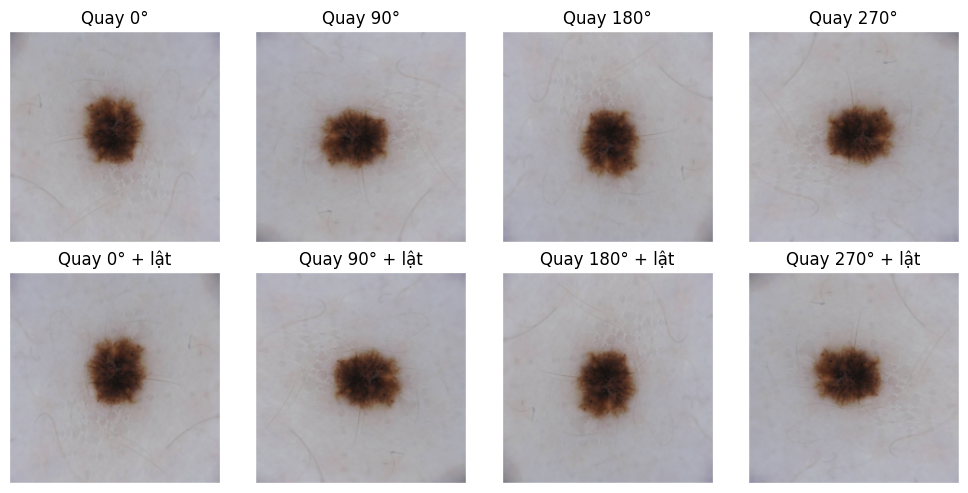

In [4]:
NORMALIZE = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([.485,.456,.406], [.229,.224,.225])
])

def d4(rgb, code):
    # Hoán vị pixel trên ảnh vuông, không nội suy ở bước D4.
    assert code in range(8)
    a = np.rot90(np.asarray(rgb), k=code % 4, axes=(0,1))
    if code >= 4:
        a = np.flip(a, axis=1)
    return Image.fromarray(np.ascontiguousarray(a))

def locate_images(frame):
    # Chỉ lập chỉ mục ảnh train/val được yêu cầu; không mở ảnh test.
    assert frame.split.isin(['train','val']).all()
    wanted = set(frame.image)
    paths = {}
    for p in IMAGE_ROOT.rglob('*'):
        if p.suffix.lower() not in {'.jpg','.jpeg','.png'} or p.stem not in wanted:
            continue
        if '.ipynb_checkpoints' in p.parts:
            continue
        assert p.stem not in paths, f'Trùng đường dẫn ảnh {p.stem}'
        paths[p.stem] = p
    assert set(paths) == wanted, f'Thiếu {len(wanted-set(paths))} ảnh'
    for row in frame.itertuples():
        assert sha_file(paths[row.image]) == row.file_sha256, row.image
        if paths[row.image].parent.name in LABELS:
            assert paths[row.image].parent.name == row.label_name
    return paths

class SkinDataset(Dataset):
    def __init__(self, frame, paths, train=False):
        self.frame = frame.reset_index(drop=True)
        self.paths, self.train = paths, train
        assert self.frame.split.eq('train' if train else 'val').all()
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(self.paths[row.image]) as source:
            rgb = source.convert('RGB').resize((SIZE,SIZE), Image.Resampling.BILINEAR)
        if self.train:
            rgb = d4(rgb, int(torch.randint(0,8,(1,)).item()))
        return NORMALIZE(rgb), int(row.label)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    random.seed(worker_seed); np.random.seed(worker_seed)

def make_loader(frame, paths, train=False):
    return DataLoader(SkinDataset(frame, paths, train), batch_size=BATCH,
        shuffle=train, num_workers=WORKERS, pin_memory=True, drop_last=False,
        worker_init_fn=seed_worker, generator=torch.Generator().manual_seed(SEED))

# Một ảnh train để quan sát phép biến đổi; không chọn theo độ đẹp hoặc dự đoán.
example = parts['train'].sort_values('image').iloc[[0]]
example_path = locate_images(example)[example.iloc[0].image]
with Image.open(example_path) as im:
    rgb = im.convert('RGB').resize((SIZE,SIZE), Image.Resampling.BILINEAR)
fig, axes = plt.subplots(2,4,figsize=(10,5))
for k, ax in enumerate(axes.flat):
    ax.imshow(d4(rgb,k)); ax.set_title(f'Quay {90*(k%4)}°' + (' + lật' if k>=4 else '')); ax.axis('off')
plt.tight_layout(); plt.show()

### Đọc hình minh họa D4

Tám hình là **cùng một ảnh train ở tám hướng**, không phải tám tổn thương khác nhau:
- Bốn góc quay: **0°, 90°, 180°, 270°**.
- Bốn góc quay trên kết hợp **lật ngang**.

Khi train, mỗi lần lấy ảnh, chương trình chọn ngẫu nhiên **một phép biến đổi**. Mục đích là giúp mô hình bớt phụ thuộc vào hướng chụp; không tạo thêm bệnh nhân hay tổn thương mới.

Quay/lật D4 chỉ hoán vị pixel trên ảnh đã resize. Bước resize trước đó vẫn có nội suy, nên không nói toàn bộ pipeline bảo toàn 100% chi tiết ảnh.

**Validation và demo chỉ resize, chuyển tensor và normalize; không dùng D4 ngẫu nhiên.**

## 3. Kiến trúc ResNet50 và transfer learning
ResNet cộng đầu vào qua nhánh tắt với phần biến đổi học được: **F(x)+x** (dùng phép chiếu khi kích thước khác). Điều này giúp truyền gradient và tối ưu mạng sâu thuận lợi hơn, không đảm bảo hết overfitting. Bottleneck dùng các tích chập **1×1 → 3×3 → 1×1**. Mạng học đặc trưng từ ảnh; không cung cấp trực tiếp đặc trưng lâm sàng do bác sĩ chú giải.

Khởi tạo bằng **ImageNet V1**, thay `fc` thành tám đầu ra; fine-tune toàn mạng, gồm BatchNorm. Không có giai đoạn đóng băng rồi mở dần.

| So sánh cùng nền D4 + CE | Val Macro-F1 |
|---|---:|
| T02B — ResNet50 | **60,3002%** |
| M01 — EfficientNet-B0 | **58,4366%** |

Nguồn: `experiments_seed42.csv`. M01 chưa cải thiện trong ngân sách đã thử; không kết luận ResNet50 luôn hơn B0. **T02A là ResNet50 với augmentation HV**, không phải ResNet18. Chuỗi ResNet18 khác split/loss/augmentation nên không đưa vào so sánh trực tiếp kiến trúc.

Khi demo, tạo kiến trúc với `weights=None` rồi nạp toàn bộ checkpoint đã huấn luyện. Điều này tránh tải lại ImageNet, không phải học từ trọng số ngẫu nhiên.

In [5]:
def reset_seed():
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def build_model(pretrained=True):
    weights = models.ResNet50_Weights.IMAGENET1K_V1 if pretrained else None
    model = models.resnet50(weights=weights)
    model.fc = nn.Linear(model.fc.in_features, len(LABELS))
    for p in model.parameters():
        p.requires_grad = True
    return model.to(DEVICE)

# Chỉ định nghĩa; model được tạo khi chủ động bật train hoặc demo.
print('ResNet50, fc: 2048 → 8, fine-tune toàn mạng. Chưa nạp model.')

ResNet50, fc: 2048 → 8, fine-tune toàn mạng. Chưa nạp model.


### Vì sao chương trình ghi “Chưa nạp model”?

Cell này mới **định nghĩa cách tạo mô hình**. Mô hình chỉ được tạo khi gọi hàm trong phần train hoặc demo, nên thông báo này không phải lỗi.

`fc: 2048 → 8` nghĩa là lớp phân loại cuối nhận **2.048 đặc trưng do mạng học được** và tạo **tám điểm số**, tương ứng tám nhãn.

Khi train, mô hình bắt đầu từ trọng số ImageNet và học tiếp trên ảnh soi da. Khi demo, chương trình nạp checkpoint T02B đã huấn luyện, **không học lại từ đầu**.

## 4. Loss và đối chứng chiến lược huấn luyện
Cross-Entropy không trọng số phạt mô hình khi điểm dành cho nhãn đúng thấp. PyTorch nhận **logits**, không đưa softmax vào trước `CrossEntropyLoss`.

| Run | Thay đổi | Val Macro-F1 (%) | Δ so T02B (điểm %) |
| --- | --- | --- | --- |
| B00 | Không augmentation | 55.2115 | -5.0887 |
| T02A | HV | 58.5276 | -1.7725 |
| T02B | D4 + CE thường | 60.3002 | +0.0000 |
| SoG | Thêm chuẩn hóa màu | 58.5396 | -1.7606 |
| L01 | CE trọng số nghịch căn số ảnh train | 60.3251 | +0.0249 |
| S01 | Sampling cân bằng + CE thường | 58.4844 | -1.8157 |
| F01 | LR backbone thấp hơn | 58.9639 | -1.3362 |
| M01 | EfficientNet-B0 | 58.4366 | -1.8636 |

Nguồn: `experiments_seed42.csv`. Không đổi mã thành T01B/T03B/T04B vì không có nguồn tương ứng các số trong đề xuất.

**L01 nhỉnh hơn khoảng 0,0249 điểm %, CI95 chứa 0**; chưa đủ bằng chứng thay T02B. Sampling cân bằng cũng chưa cải thiện trong lượt đã thử. Không gọi các mô hình này “đoán bừa”, không quy nguyên nhân cho trọng số quá lớn nếu chưa phân tích cụ thể precision/recall và lỗi. D4 không thay đổi phân phối số ảnh giữa lớp. Giữ CE thường vì đơn giản và bằng chứng hiện có chưa ủng hộ thay đổi.

Macro-F1 là tiêu chí **đánh giá và chọn checkpoint**; CE là hàm **tối ưu khi học**, hai vai trò khác nhau.

In [6]:
criterion = nn.CrossEntropyLoss()  # Không class weights, không weighted sampler.

def metrics(y, pred):
    return dict(accuracy=accuracy_score(y,pred),
        balanced_accuracy=balanced_accuracy_score(y,pred),
        macro_f1=f1_score(y,pred,labels=LABELS,average='macro',zero_division=0))

def tables(y, pred):
    p,r,f,s = precision_recall_fscore_support(y,pred,labels=LABELS,zero_division=0)
    per_class = pd.DataFrame(dict(label=LABELS,precision=p,recall=r,f1=f,support=s))
    return per_class, confusion_matrix(y,pred,labels=LABELS)

### Cell này không hiện output có phải lỗi không?

Không. Cell mới khai báo loss và các hàm đánh giá; chúng được dùng ở những phần sau.

| Chỉ số | Cách hiểu |
|---|---|
| Accuracy | Trong toàn bộ ảnh, bao nhiêu ảnh được dự đoán đúng? |
| Precision của một lớp | Trong những ảnh được dự đoán là lớp đó, bao nhiêu ảnh đúng? |
| Recall của một lớp | Trong những ảnh thật sự thuộc lớp đó, mô hình tìm đúng bao nhiêu? |
| F1 | Kết hợp precision và recall bằng trung bình điều hòa |
| Macro-F1 | Trung bình F1 của tám lớp, mỗi lớp có trọng số ngang nhau |
| Balanced accuracy | Trung bình recall của tám lớp |
| Support | Số ảnh có nhãn thật thuộc lớp đó |

**Cross-Entropy dùng để hướng dẫn mô hình học; Macro-F1 dùng để đánh giá và chọn checkpoint.** Đây là hai vai trò khác nhau.

## 5. Optimizer, scheduler và early stopping
**AdamW:** LR **10⁻⁴**, weight decay **10⁻⁴** cho toàn mạng. Weight decay tách khỏi bước cập nhật thích nghi, là một hình thức regularization; không bảo đảm tránh quá khớp.

**CosineAnnealingLR:** `T_max=16`, giảm LR theo lịch cosin; không chứng minh hội tụ tới cực tiểu tốt nhất. `scheduler.step()` gọi cuối epoch.

**Early stopping:** tối đa **16 epoch**, patience **4**, chỉ lưu khi `val_macro_f1 > best + 10⁻⁵`. Epoch có loss thấp nhất không nhất thiết có macro-F1 cao nhất. Seed **42** giúp kiểm soát ngẫu nhiên trong môi trường cố định; không đảm bảo mọi máy cho kết quả bit giống nhau.

In [7]:
def make_optimizer(model):
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    return optimizer, scheduler

class EarlyStopping:
    def __init__(self, path, patience=PATIENCE, min_delta=MIN_DELTA):
        self.path, self.patience, self.min_delta = path, patience, min_delta
        self.best, self.wait, self.best_epoch = -1., 0, None
    def update(self, score, model, epoch):
        if not np.isfinite(score):
            raise ValueError('Macro-F1 không hữu hạn')
        if score > self.best + self.min_delta:
            self.best, self.wait, self.best_epoch = score, 0, epoch
            torch.save(model.state_dict(), self.path)
        else:
            self.wait += 1
        return self.wait >= self.patience

### Mô hình được cập nhật và dừng học như thế nào?

Cell này mới định nghĩa các công cụ, **chưa cập nhật trọng số**:

- **AdamW:** cập nhật trọng số để giảm loss.
- **Learning rate = 0,0001:** kiểm soát độ lớn bước cập nhật.
- **Cosine scheduler:** giảm learning rate theo lịch đã đặt.
- **Early stopping:** dừng nếu validation Macro-F1 không cải thiện đủ ngưỡng trong **4 epoch liên tiếp**.

Ví dụ, nếu epoch 10 tốt nhất và epoch 11–14 không cải thiện, chương trình dừng sau epoch 14 rồi nạp lại checkpoint epoch 10. Dù chưa dừng sớm, ngân sách vẫn giới hạn tối đa **16 epoch**.

**Checkpoint là file lưu trọng số mô hình tại thời điểm được chọn.**

## 6. Huấn luyện T02B tùy chọn — FP32 theo protocol
**Không bật AMP trong bản này:** các run lịch sử dùng FP32. AMP là thay đổi cách tính toán, muốn thử phải có thí nghiệm riêng. T02B seed42 lịch sử chọn **epoch 14/16**, không phải epoch12; validation macro-F1 **60,3002%**.

Mỗi batch: xóa gradient → forward → CE → backward → AdamW cập nhật. Sau mỗi epoch: validation → ghi history → lưu best checkpoint → scheduler → xét dừng. Chỉ có T02B; không có vòng lặp qua phương án.

`RUN_TRAIN=False` mặc định. Khi bật, bắt đầu từ ImageNet, xuất thư mục mới và không thay checkpoint dùng báo cáo. Mã gọn được tổ chức lại, chưa được xác nhận tái lập toàn bộ run lịch sử. Bằng chứng preflight thành công trước đây thuộc notebook nguồn cũ, không tự chuyển sang bản này.

In [8]:
def train_one_epoch(model, loader, optimizer):
    model.train()  # BatchNorm học thống kê trong train.
    loss_sum, total = 0., 0
    for images, y in loader:
        images, y = images.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits,y)
        if not torch.isfinite(loss):
            raise ValueError('Train loss NaN/Inf')
        loss.backward(); optimizer.step()
        loss_sum += loss.item()*len(y); total += len(y)
    return loss_sum/total

@torch.inference_mode()
def validate(model, loader):
    model.eval()
    loss_sum, total, probabilities, targets = 0., 0, [], []
    for images, y in loader:
        images, y = images.to(DEVICE), y.to(DEVICE)
        logits = model(images); loss = criterion(logits,y)
        if not torch.isfinite(logits).all() or not torch.isfinite(loss):
            raise ValueError('Validation NaN/Inf')
        loss_sum += loss.item()*len(y); total += len(y)
        probabilities.append(logits.softmax(1).cpu().numpy()); targets.extend(y.cpu().tolist())
    prob = np.concatenate(probabilities)
    y = np.array(LABELS)[targets]; pred = np.array(LABELS)[prob.argmax(1)]
    return loss_sum/total, metrics(y,pred), prob

def check_training_environment():
    import torchvision, PIL, sklearn, platform, multiprocessing
    actual = dict(torch=torch.__version__,torchvision=torchvision.__version__,
        numpy=np.__version__,pandas=pd.__version__,sklearn=sklearn.__version__,pillow=PIL.__version__)
    expected = lock['baseline_config']['environment']
    for key,value in actual.items():
        assert value == expected[key], f'Lệch {key}: {value} / {expected[key]}'
    assert platform.system() == 'Linux' and multiprocessing.get_context().get_start_method() == 'fork'
    assert torch.cuda.is_available() and 'T4' in torch.cuda.get_device_name(0)
    return actual

new_history = None
if not RUN_TRAIN:
    print('TRAIN NOT_RUN: đọc kết quả lịch sử để báo cáo.')
else:
    train_out = OUT/'fresh_training'; train_out.mkdir(exist_ok=False)
    try:
        save_json(train_out/'environment.json',check_training_environment())
        paths = locate_images(pd.concat([parts['train'],parts['val']]))
        reset_seed(); model = build_model()
        initial = hashlib.sha256()
        for key,value in model.state_dict().items():
            initial.update(key.encode()); initial.update(value.detach().cpu().numpy().tobytes())
        assert initial.hexdigest() == '37a03a16d86fda7f927000366760327e605b16fc8b4cb6a565a4ce763fe9003c', 'Khởi tạo khác protocol'
        save_json(train_out/'initial.json',dict(initial_sha=initial.hexdigest()))
        print('Tham số trainable:',sum(p.numel() for p in model.parameters() if p.requires_grad))
        train_loader = make_loader(parts['train'],paths,True)
        val_loader = make_loader(parts['val'],paths,False)
        optimizer,scheduler = make_optimizer(model)
        early = EarlyStopping(train_out/'best_resnet50.pt')
        rows = []
        save_json(train_out/'config.json',dict(method='T02B_D4_R50',seed=SEED,size=SIZE,batch=BATCH,
            workers=WORKERS,epochs=EPOCHS,patience=PATIENCE,min_delta=MIN_DELTA,amp=False,
            lr=1e-4,weight_decay=1e-4,split_sha=sha_file(REPORT_DATA/'split_manifest.csv'),
            labels=LABELS,new_implementation=True))
        for epoch in range(1,EPOCHS+1):
            train_loss = train_one_epoch(model,train_loader,optimizer)
            val_loss,scores,_ = validate(model,val_loader)
            rows.append(dict(epoch=epoch,train_loss=train_loss,val_loss=val_loss,
                lr=optimizer.param_groups[0]['lr'],**scores))
            pd.DataFrame(rows).to_csv(train_out/'history.csv',index=False)
            print(f'Epoch {epoch:02d}: loss={train_loss:.4f}; val F1={scores["macro_f1"]:.4f}')
            stop_now = early.update(scores['macro_f1'],model,epoch)
            scheduler.step()
            if stop_now: break
        model.load_state_dict(torch.load(early.path,map_location=DEVICE,weights_only=True),strict=True)
        val_loss,scores,prob = validate(model,val_loader)
        predictions = parts['val'][['image','group','file_sha256']].copy()
        predictions['true_label'] = parts['val'].label_name.to_numpy()
        predictions['pred_label'] = np.array(LABELS)[prob.argmax(1)]
        for i,label in enumerate(LABELS): predictions['p_'+label] = prob[:,i]
        predictions.to_csv(train_out/'val_predictions.csv',index=False)
        pc,cm = tables(predictions.true_label,predictions.pred_label)
        pc.to_csv(train_out/'val_per_class.csv',index=False)
        pd.DataFrame(cm,index=LABELS,columns=LABELS).to_csv(train_out/'val_confusion.csv')
        save_json(train_out/'complete.json',dict(status='COMPLETED',metrics=scores,val_loss=val_loss,
            best_epoch=early.best_epoch,completed_epochs=len(rows),checkpoint_sha=sha_file(early.path)))
        new_history = pd.DataFrame(rows)
    except Exception as exc:
        save_json(train_out/'STOP.json',dict(status='STOP',error=str(exc)))
        raise

TRAIN NOT_RUN: đọc kết quả lịch sử để báo cáo.


### Đọc thông báo TRAIN NOT_RUN

Phiên này đặt **RUN_TRAIN=False**, nên không huấn luyện mới. Các bảng thực nghiệm trong notebook là kết quả đã chạy và lưu trước đây.

Nếu bật train, quy trình mỗi batch là:
**Dự đoán → tính loss → tính gradient → cập nhật trọng số.**

Sau mỗi epoch, mô hình được đánh giá trên validation và lưu checkpoint nếu Macro-F1 cải thiện.

Nhánh train của bản notebook gọn này **chưa được chạy trọn vẹn trên Kaggle**. Phần báo cáo và demo đã chạy thành công không đồng nghĩa phần train đã được kiểm đầy đủ.

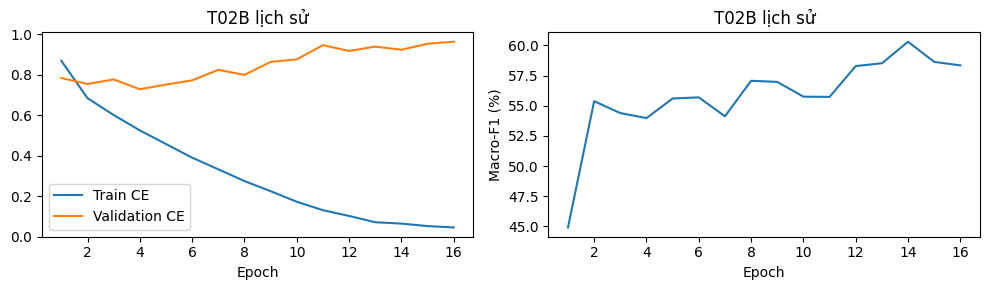

Loss thấp không đồng nghĩa F1 cao; chọn checkpoint theo macro-F1.


In [9]:
# Đường cong lịch sử, hoặc của run mới nếu chủ động train trong phiên này.
history = new_history if new_history is not None else pd.read_csv(REPORT_DATA/'T02B_history.csv')
origin = 'Run mới' if new_history is not None else 'T02B lịch sử'
fig,axes = plt.subplots(1,2,figsize=(10,3))
axes[0].plot(history.epoch,history.train_loss,label='Train CE')
axes[0].plot(history.epoch,history.val_loss,label='Validation CE'); axes[0].legend()
axes[1].plot(history.epoch,history.macro_f1*100,label='Validation macro-F1')
for ax in axes: ax.set_xlabel('Epoch'); ax.set_title(origin)
axes[1].set_ylabel('Macro-F1 (%)'); plt.tight_layout(); plt.show()
print('Loss thấp không đồng nghĩa F1 cao; chọn checkpoint theo macro-F1.')

### Xác nhận D4 bằng seed mới (kết quả lịch sử)
| Seed | B00 Macro-F1 | T02B Macro-F1 | Δ điểm % | CI95 của Δ theo group |
|---|---:|---:|---:|---|
| 42 — thăm dò | 55,2115% | 60,3002% | +5,0887 | [+0,1739; +9,3884] |
| 43 — xác nhận | 57,3231% | 57,7945% | +0,4714 | [−3,7991; +5,1088] |
| 44 — xác nhận | 56,0809% | 59,9743% | +3,8934 | [−0,8558; +8,6463] |

Nguồn: `experiments_seed42.csv`, `r02/PAIRED_DELTA_BY_SEED.csv`. Hai seed mới có Δ trung bình **+2,1824 điểm %**, sample SD **2,4197 điểm %**. Cả ba tăng F1 nhưng mức tăng dao động; hai CI mới chứa 0. Seed43 accuracy giảm **1,4573 điểm %**. Bootstrap theo group phản ánh bất định lấy mẫu validation, không phải biến thiên seed. Tái dùng validation để sàng lọc nhiều phương án làm giới hạn kết luận.

## 7. Đánh giá test nội bộ của checkpoint đã chốt
**Chỉ đọc predictions đã lưu** và tính lại metrics. Không tạo test_loader hay chạy test lại cho mô hình mới. Test gồm **5.065 ảnh nội bộ**, không phải official test của ISIC. Test đã được đánh giá trước đợt mở rộng chín phương án tiền xử lý; các run mở rộng dùng validation và không thay checkpoint đã chốt.

T02B seed42: **Accuracy 76,4265%; Macro-F1 60,5402%; balanced accuracy 58,8512%; macro-precision 63,1779%; weighted-F1 75,7769%**.

| Lớp | Precision (%) | Recall (%) | F1 (%) | Support |
| --- | --- | --- | --- | --- |
| MEL | 72.99 | 58.24 | 64.78 | 965 |
| NV | 84.41 | 90.56 | 87.38 | 2607 |
| BCC | 70.84 | 80.03 | 75.16 | 601 |
| AK | 44.63 | 31.40 | 36.86 | 172 |
| BKL | 62.03 | 60.77 | 61.40 | 492 |
| DF | 56.52 | 40.62 | 47.27 | 32 |
| VASC | 77.03 | 71.25 | 74.03 | 80 |
| SCC | 36.97 | 37.93 | 37.45 | 116 |

Nguồn: `test_report/final_test/predictions.csv` và `per_class.csv`; bảng được đối chiếu với `final_test_per_class.csv` trong ZIP PRESENTATION. Không có nguồn đối chứng B00 test ở đây, nên **không ghi mức tăng F1 từng lớp do D4 trên test**. Không dùng số test khác nguồn ghép vào checkpoint này. Macro-precision và weighted-F1 được tính trực tiếp từ predictions trong cell dưới.

Recall AK/SCC thấp là hạn chế cần nêu. Không chứng minh khả năng chẩn đoán lâm sàng hoặc tổng quát hóa tới bệnh viện khác.

,accuracy,balanced_accuracy,macro_f1,macro_precision,weighted_f1
validation_replay,76.9988,58.6105,60.3002,64.3293,76.4869
final_test,76.4265,58.8512,60.5402,63.1779,75.7769


,label,precision,recall,f1,support
0,MEL,0.729870,0.582383,0.647839,965
1,NV,0.844119,0.905639,0.873797,2607
2,BCC,0.708395,0.800333,0.751563,601
3,AK,0.446281,0.313953,0.368601,172
4,BKL,0.620332,0.607724,0.613963,492
5,DF,0.565217,0.406250,0.472727,32
6,VASC,0.770270,0.712500,0.740260,80
7,SCC,0.369748,0.379310,0.374468,116


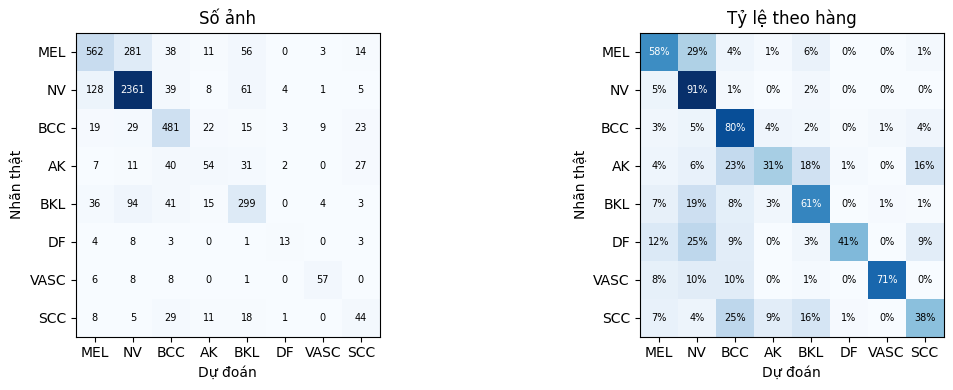

Không suy luận test mới; đây là metrics của checkpoint lịch sử.


In [10]:
saved = {}
for name, split in [('validation_replay','val'),('final_test','test')]:
    pred = pd.read_csv(REPORT_DATA/f'test_report/{name}/predictions.csv').sort_values('image').reset_index(drop=True)
    ref = parts[split].sort_values('image').reset_index(drop=True)
    assert pred.image.is_unique and len(pred)==len(ref)
    for left,right in [('image','image'),('group','group'),('file_sha256','file_sha256'),('true_label','label_name')]:
        assert pred[left].tolist()==ref[right].tolist()
    probs = pred[['p_'+l for l in LABELS]].to_numpy()
    assert np.isfinite(probs).all() and ((probs>=0)&(probs<=1)).all()
    assert np.allclose(probs.sum(1),1,atol=1e-6,rtol=0)
    assert (np.array(LABELS)[probs.argmax(1)]==pred.pred_label).all()
    scores = metrics(pred.true_label,pred.pred_label)
    expected = read_json(f'test_report/{name}/metrics.json')
    assert all(abs(scores[k]-expected[k])<=1e-8 for k in scores)
    pc,cm = tables(pred.true_label,pred.pred_label)
    scores['macro_precision'] = float(pc.precision.mean())
    scores['weighted_f1'] = float(np.average(pc.f1,weights=pc.support))
    saved[name] = (pred,scores,pc,cm)
    pc.to_csv(OUT/f'{name}_per_class.csv',index=False)
    pd.DataFrame(cm,index=LABELS,columns=LABELS).to_csv(OUT/f'{name}_confusion.csv')
display(pd.DataFrame({k:v[1] for k,v in saved.items()}).T.mul(100).round(4))
display(saved['final_test'][2])
cm = saved['final_test'][3]
fig,axes = plt.subplots(1,2,figsize=(12,4))
for ax,normalized in zip(axes,[False,True]):
    values = cm/cm.sum(1,keepdims=True) if normalized else cm
    ax.imshow(values,cmap='Blues')
    ax.set_xticks(range(8),LABELS); ax.set_yticks(range(8),LABELS)
    ax.set_xlabel('Dự đoán'); ax.set_ylabel('Nhãn thật')
    ax.set_title('Tỷ lệ theo hàng' if normalized else 'Số ảnh')
    for i in range(8):
        for j in range(8):
            text = f'{values[i,j]:.0%}' if normalized else str(cm[i,j])
            ax.text(j,i,text,ha='center',va='center',fontsize=7,
                color='white' if values[i,j]>values.max()/2 else 'black')
plt.tight_layout(); plt.savefig(OUT/'test_confusion.png',dpi=150); plt.show()
print('Không suy luận test mới; đây là metrics của checkpoint lịch sử.')

### Đọc bảng kết quả và ma trận nhầm lẫn

**Bảng tổng thể dùng đơn vị %:**

| Chỉ số test | Giá trị | Ý nghĩa |
|---|---:|---|
| Accuracy | **76,4265%** | Tỷ lệ ảnh được dự đoán đúng |
| Macro-F1 | **60,5402%** | Trung bình F1 của tám lớp |
| Balanced accuracy | **58,8512%** | Trung bình recall của tám lớp |
| Macro-precision | **63,1779%** | Trung bình precision của tám lớp |
| Weighted-F1 | **75,7769%** | Trung bình F1 có trọng số theo số ảnh từng lớp |

Macro-F1 60,54% **không có nghĩa 60,54% số ảnh được đoán đúng**. Tỷ lệ ảnh đúng là accuracy.

**Bảng từng lớp phía dưới dùng thang 0–1:** ví dụ recall AK `0.313953` nghĩa là khoảng **31,40%** ảnh AK được nhận diện đúng. Support AK là **172 ảnh**.

**Hai confusion matrix:**
- Hàng là **nhãn thật**, cột là **nhãn dự đoán**.
- Ô trên đường chéo là dự đoán đúng; ô ngoài đường chéo là nhầm.
- Hình trái ghi **số ảnh**.
- Hình phải ghi **tỷ lệ trong từng hàng**, giúp so sánh các lớp dù số ảnh khác nhau.

NV có recall khoảng **90,56%**, nhưng AK chỉ **31,40%** và SCC **37,93%**. Vì vậy, kết quả giữa các lớp còn chưa đồng đều.

Đây là tính lại từ dự đoán đã lưu của checkpoint đã chốt, **không phải suy luận test mới**.

## 8. Demo dự đoán một ảnh
Chọn `correct` hoặc `wrong` theo dự đoán **validation lịch sử**, đổi `DEMO_INDEX` để chọn ảnh khác; đây không phải ép model trả lời đúng/sai. Hoặc `path` để dùng ảnh ngoài. Chặn ảnh test đã biết theo tên/hash; không dùng test làm gallery demo.

Hàm nạp đúng checkpoint lịch sử, không dùng model vừa train. Hiển thị ảnh và **Top-3 softmax**, đồng thời lưu đủ tám giá trị. Softmax tổng bằng 1 nhưng **chưa hiệu chuẩn thành xác suất chẩn đoán**; model buộc chọn một trong tám nhãn kể cả ảnh ngoài phạm vi.

Hai ví dụ đúng/sai là minh họa có chủ đích, không ước lượng accuracy. Khi trình bày: “Em đưa ảnh vào mô hình đã học, không huấn luyện lại; kết quả đúng/sai đọc bằng cách so với nhãn dataset.”

Dự đoán: BKL | Nhãn thật: NV
SAI
Softmax chưa hiệu chuẩn; không phải xác suất chẩn đoán.


,label,softmax
0,MEL,0.013517
1,NV,0.035536
2,BCC,0.000025
3,AK,0.000165
4,BKL,0.950606
5,DF,0.000009
6,VASC,0.000051
7,SCC,0.000090


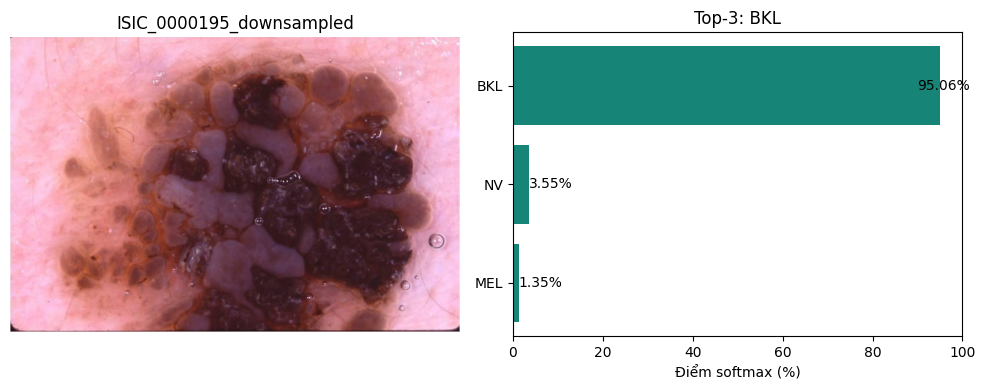

Output: /kaggle/working/T02B_CLEAN_20261027_001944_940980.zip


In [11]:
RUN_DEMO = True
DEMO_MODE = 'wrong'  # correct / wrong / path
DEMO_INDEX = 1
DEMO_IMAGE_PATH = None

def load_demo_model():
    if CHECKPOINT_PATH is None:
        matches = [p for p in IMAGE_ROOT.rglob('best_resnet50.pt') if sha_file(p)==complete['checkpoint_sha']]
        assert matches, 'Thiếu checkpoint T02B seed42: gắn FULL Output T02AB.'
        path = matches[0]
    else:
        path = Path(CHECKPOINT_PATH)
    assert sha_file(path)==complete['checkpoint_sha'], 'Sai checkpoint lịch sử'
    model = build_model(pretrained=False)
    model.load_state_dict(torch.load(path,map_location=DEVICE,weights_only=True),strict=True)
    return model.eval()

@torch.inference_mode()
def predict_single_image(model, image_path, true_label=None):
    path = Path(image_path); digest = sha_file(path)
    by_name = manifest[manifest.image.eq(path.stem)]
    by_hash = manifest[manifest.file_sha256.eq(digest)]
    known = pd.concat([by_name,by_hash])
    assert not known.split.eq('test').any(), 'Không demo ảnh test đã khóa.'
    assert by_name.empty or by_name.file_sha256.eq(digest).all(), 'Tên ảnh có trong manifest nhưng hash khác.'
    if not by_hash.empty:
        assert by_hash.label_name.nunique()==1 and by_hash.split.nunique()==1
        label = by_hash.iloc[0].label_name
        assert true_label is None or true_label==label, 'Nhãn truyền vào không khớp manifest'
        true_label = label
    with Image.open(path) as source:
        rgb = source.convert('RGB')
    resized = rgb.resize((SIZE,SIZE),Image.Resampling.BILINEAR)
    model.eval()
    logits = model(NORMALIZE(resized).unsqueeze(0).to(DEVICE))
    assert logits.shape==(1,8) and torch.isfinite(logits).all()
    scores = logits.softmax(1)[0].cpu().numpy()
    result = pd.DataFrame({'label':LABELS,'softmax':scores})
    top = result.nlargest(3,'softmax')
    label = top.iloc[0].label
    print('Dự đoán:',label,'| Nhãn thật:',true_label)
    if true_label is not None: print('ĐÚNG' if label==true_label else 'SAI')
    print('Softmax chưa hiệu chuẩn; không phải xác suất chẩn đoán.')
    display(result)
    fig,axes = plt.subplots(1,2,figsize=(10,4))
    axes[0].imshow(rgb); axes[0].axis('off'); axes[0].set_title(path.stem)
    axes[1].barh(top.label,top.softmax*100,color='#168578'); axes[1].invert_yaxis()
    axes[1].set_xlim(0,100); axes[1].set_xlabel('Điểm softmax (%)'); axes[1].set_title('Top-3: '+label)
    for i,v in enumerate(top.softmax): axes[1].text(min(v*100,90),i,f'{v:.2%}',va='center')
    demo_out=OUT/('demo_'+datetime.now().strftime('%H%M%S_%f')); demo_out.mkdir()
    plt.tight_layout(); plt.savefig(demo_out/'prediction.png',dpi=150); plt.show()
    result.to_csv(demo_out/'softmax.csv',index=False)
    save_json(demo_out/'prediction.json',dict(image=str(path),image_sha=digest,
        checkpoint_sha=complete['checkpoint_sha'],true_label=true_label,predicted_label=label,
        softmax=[float(x) for x in scores],labels=LABELS))
    return result

if RUN_DEMO:
    assert DEMO_MODE in ['correct','wrong','path']
    if DEMO_MODE != 'path':
        val = saved['validation_replay'][0]
        ok = val.true_label.eq(val.pred_label)
        pool = val[ok if DEMO_MODE=='correct' else ~ok].sort_values('image')
        assert 0<=DEMO_INDEX<len(pool)
        selected = parts['val'][parts['val'].image.eq(pool.iloc[DEMO_INDEX].image)]
        DEMO_IMAGE_PATH = locate_images(selected)[selected.iloc[0].image]
    assert DEMO_IMAGE_PATH is not None
    demo_model = load_demo_model()
    result = predict_single_image(demo_model,DEMO_IMAGE_PATH)
    del demo_model
else:
    print('DEMO NOT_RUN. Bật RUN_DEMO rồi chạy lại cell này.')

# Chạy lại cell này sau demo để ZIP bao gồm các kết quả mới.
archive = shutil.make_archive(str(OUT),'zip',OUT)
print('Output:', archive)

### Đọc kết quả demo một ảnh

Dòng **Dự đoán / Nhãn thật / ĐÚNG–SAI** cho biết kết quả suy luận mới có khớp nhãn trong dataset hay không.

- Bảng liệt kê **đủ tám điểm softmax**, trên thang 0–1.
- Biểu đồ chỉ hiển thị **ba lớp có điểm cao nhất**, trên thang %.
- Tổng Top-3 không bắt buộc bằng 100%, vì còn năm lớp khác.
- Hình bên trái là ảnh gốc; mô hình thực sự nhận ảnh đã resize **224×224** và normalize.

**Ví dụ đang lưu trong notebook:** ảnh `ISIC_0000195_downsampled.jpg` có nhãn thật **NV**, nhưng mô hình dự đoán **BKL** với softmax khoảng **95,06%**.

Điều này cho thấy **softmax cao vẫn có thể đi kèm dự đoán sai**. Softmax chưa được hiệu chuẩn thành xác suất chẩn đoán.

Ảnh được chọn từ danh sách lỗi validation để minh họa giới hạn của mô hình; không dùng một vài ảnh demo để tính accuracy hoặc kết luận hiệu quả chung.

Đường dẫn ZIP ở cuối là nơi lưu các bảng và hình của phiên chạy.